### ⚙️ Environment Setup  
This setup uses **GROMACS 2023 + PLUMED installed in home directory on ACCRE**.  
Install Gromacs 2023 patched with plummed to your home directory and load all modules to run
Update module loads or source your own `GMXRC` if running on a different HPC to ensure the correct environment is activated.

This part changes the most when running on HPC systems other than ACCRE, since the workflow was tailored specifically for ACCRE’s environment.

In [19]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


**Load the function defined above**

In [20]:
load_gmx_plumed()

Import these modules for convenience 

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import subprocess
import os
from contextlib import contextmanager
import re
import pandas
import pathlib

**Set your working directory here. Replace this path with your own**

In [22]:
%cd /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/6ONJ

/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/6ONJ


/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v4/Compiler/gcccore/ipykernel/2025a/lib/python3.12/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


### ⚡ Energy Extraction  
**Pull out the potential energy from every replica’s `ener.edr` file** and store it as `potential.xvg` inside each temperature folder for fast, organized analysis.


In [17]:
%%bash
for T in 100 102 104 106 106.5 107 107.5 108 108.5 109 109.5 110 112 114 116 118; do
  gmx_mpi energy -f $T/ener.edr -o $T/potential.xvg <<EOF
Potential
EOF
done

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us


Statistics over 105000001 steps [ 0.0000 through 210000.0000 ps ], 1 data sets
All statistics are over 1050001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   1833.32        0.2    60.7493    1.01959  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/6ONJ
Command line:
  gmx_mpi energy -f 102/ener.edr -o 102/potential.xvg

Opened 102/ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Improper-Dih. 
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Coulomb-(SR)  
  9  Potential       10  Kinetic-En.     11  Total-Energy    12  Temperature   
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY     


Statistics over 105000001 steps [ 0.0000 through 210000.0000 ps ], 1 data sets
All statistics are over 1050001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   1923.63       0.27    63.6433  -0.568868  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/6ONJ
Command line:
  gmx_mpi energy -f 104/ener.edr -o 104/potential.xvg

Opened 104/ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Improper-Dih. 
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Coulomb-(SR)  
  9  Potential       10  Kinetic-En.     11  Total-Energy    12  Temperature   
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY     

...


Statistics over 105000001 steps [ 0.0000 through 210000.0000 ps ], 1 data sets
All statistics are over 1050001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   3254.09       0.72    58.4378     4.6155  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/6ONJ
Command line:
  gmx_mpi energy -f 116/ener.edr -o 116/potential.xvg

Opened 116/ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Improper-Dih. 
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Coulomb-(SR)  
  9  Potential       10  Kinetic-En.     11  Total-Energy    12  Temperature   
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY     


Statistics over 105000001 steps [ 0.0000 through 210000.0000 ps ], 1 data sets
All statistics are over 1050001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   3311.02       0.49    57.7936    3.20434  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/6ONJ
Command line:
  gmx_mpi energy -f 118/ener.edr -o 118/potential.xvg

Opened 118/ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Improper-Dih. 
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Coulomb-(SR)  
  9  Potential       10  Kinetic-En.     11  Total-Energy    12  Temperature   
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY     


Statistics over 105000001 steps [ 0.0000 through 210000.0000 ps ], 1 data sets
All statistics are over 1050001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   3366.86       0.26    58.1003    1.74591  (kJ/mol)


### 📊 Energy Distribution Plot  
Creates overlapping histograms of **potential energy** from all temperature replicas to visualize sampling quality.

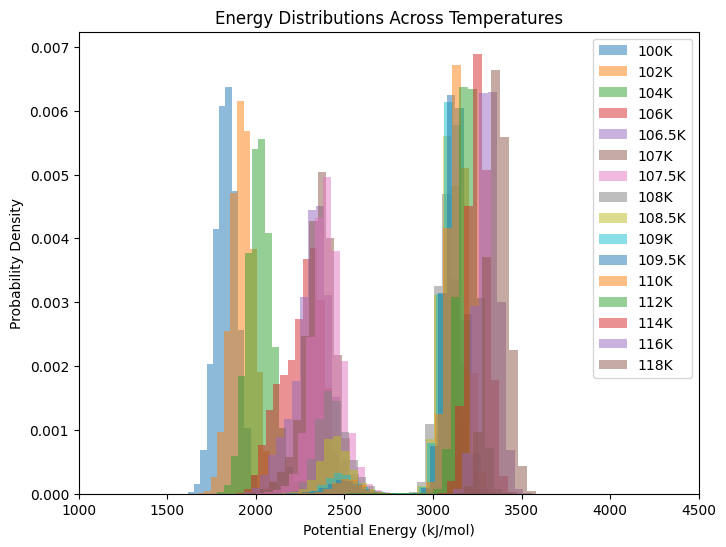

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import glob

temps = [100,102,104,106,106.5,107,107.5,108,108.5, 109, 109.5,110,112,114,116,118]
plt.figure(figsize=(8,6))

for T in temps:
    data = np.loadtxt(f"{T}/potential.xvg", comments=["@", "#"])
    E = data[:,1]
    plt.hist(E, bins=100, density=True, alpha=0.5, label=f"{T}K")

plt.xlabel("Potential Energy (kJ/mol)")
plt.ylabel("Probability Density")
plt.legend()
plt.title("Energy Distributions Across Temperatures")
plt.xlim(1000, 4500)

plt.show()


### 🔍 Concise Explanation of the Energy Distribution Plot

The energy distributions reveal three distinct regimes:
                                       
###  <p style="text-align:center; font-size:20px;"><b>N ⟷ I ⟷ U</b></p>

- **N 🔶 100–104 K → Native Basin (~1900 kJ/mol)**  
  The energy histograms are tightly centered around ~1900 kJ/mol, indicating that the system predominantly samples **native-like conformations** in this temperature range.

- **I 🔷 106–108 K → Intermediate State (~2400 kJ/mol)**  
  As temperature increases, the distributions shift toward ~2400 kJ/mol, reflecting the **emergence and stabilization of the intermediate state**.  
  Importantly, there is **good overlap** between the native and intermediate basins, ensuring smooth replica exchange across this transition.

- **U 🔺 >2800 kJ/mol → Unfolded Basin (Sampling Gap)**  
  Beyond ~3000 kJ/mol, corresponding to the **unfolded ensemble**, there is a clear **sampling gap**.  
  This is **not a concern** for our current objectives, as the focus of the analysis is on the **native ↔ intermediate** transition rather than the fully unfolded state.

---

### 📌 Summary

The plot shows a clear shift in potential energy with temperature, revealing the emergence of a well-defined **intermediate state**. Because SMOG models are particularly effective at resolving **folding intermediates and transition pathways**, the distinct peak near ~2400 kJ/mol strongly supports the presence of a stabilized intermediate basin. In contrast, the transition to the unfolded state occurs only at much higher energies, producing a sharper, more discontinuous jump.
_____________________


### 🔀 Replica Demultiplexing  
Run the **demux.pl** script (taken from the repository: https://github.com/srnas/demux/tree/master) to generate the replica–temperature mapping from your REMD logs:

In [7]:
!demux.pl 100/md.log

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

### 🔄 Walker Exchange Visualization  
Plot the **replica–temperature movement** across the temperature ladder to verify proper SMOG REMD mixing and walker mobility

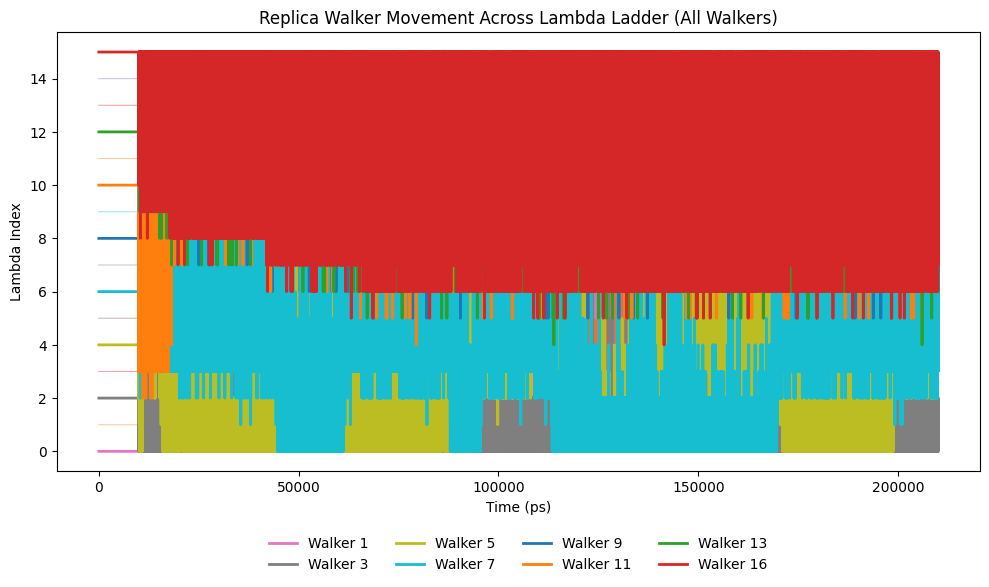

In [14]:
import numpy as np
import matplotlib.pyplot as plt

rep = np.loadtxt("replica_temp.xvg", comments=["#", "@"])
time = rep[:,0]

plt.figure(figsize=(10,6))

# choose representative walkers (change list if needed)
walkers_to_label = np.linspace(1, rep.shape[1]-1, 8, dtype=int)

for i in range(1, rep.shape[1]):
    plt.plot(time, rep[:,i], linewidth=0.8, alpha=0.4)

# overlay selected walkers thicker + labeled
for w in walkers_to_label:
    plt.plot(time, rep[:,w], linewidth=2, label=f"Walker {w}")

plt.xlabel("Time (ps)")
plt.ylabel("Lambda Index")
plt.title("Replica Walker Movement Across Lambda Ladder (All Walkers)")

# 📍 Legend below plot
plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False
)

plt.tight_layout()
plt.show()


### 📌 Note  
When plotting all walkers together, **walkers 1–16 overlap heavily**, making the visualization unclear.  
To focus on specific walkers, adjust:
Let's plot all walkers individually to visualize the movement across temperature ladder. 


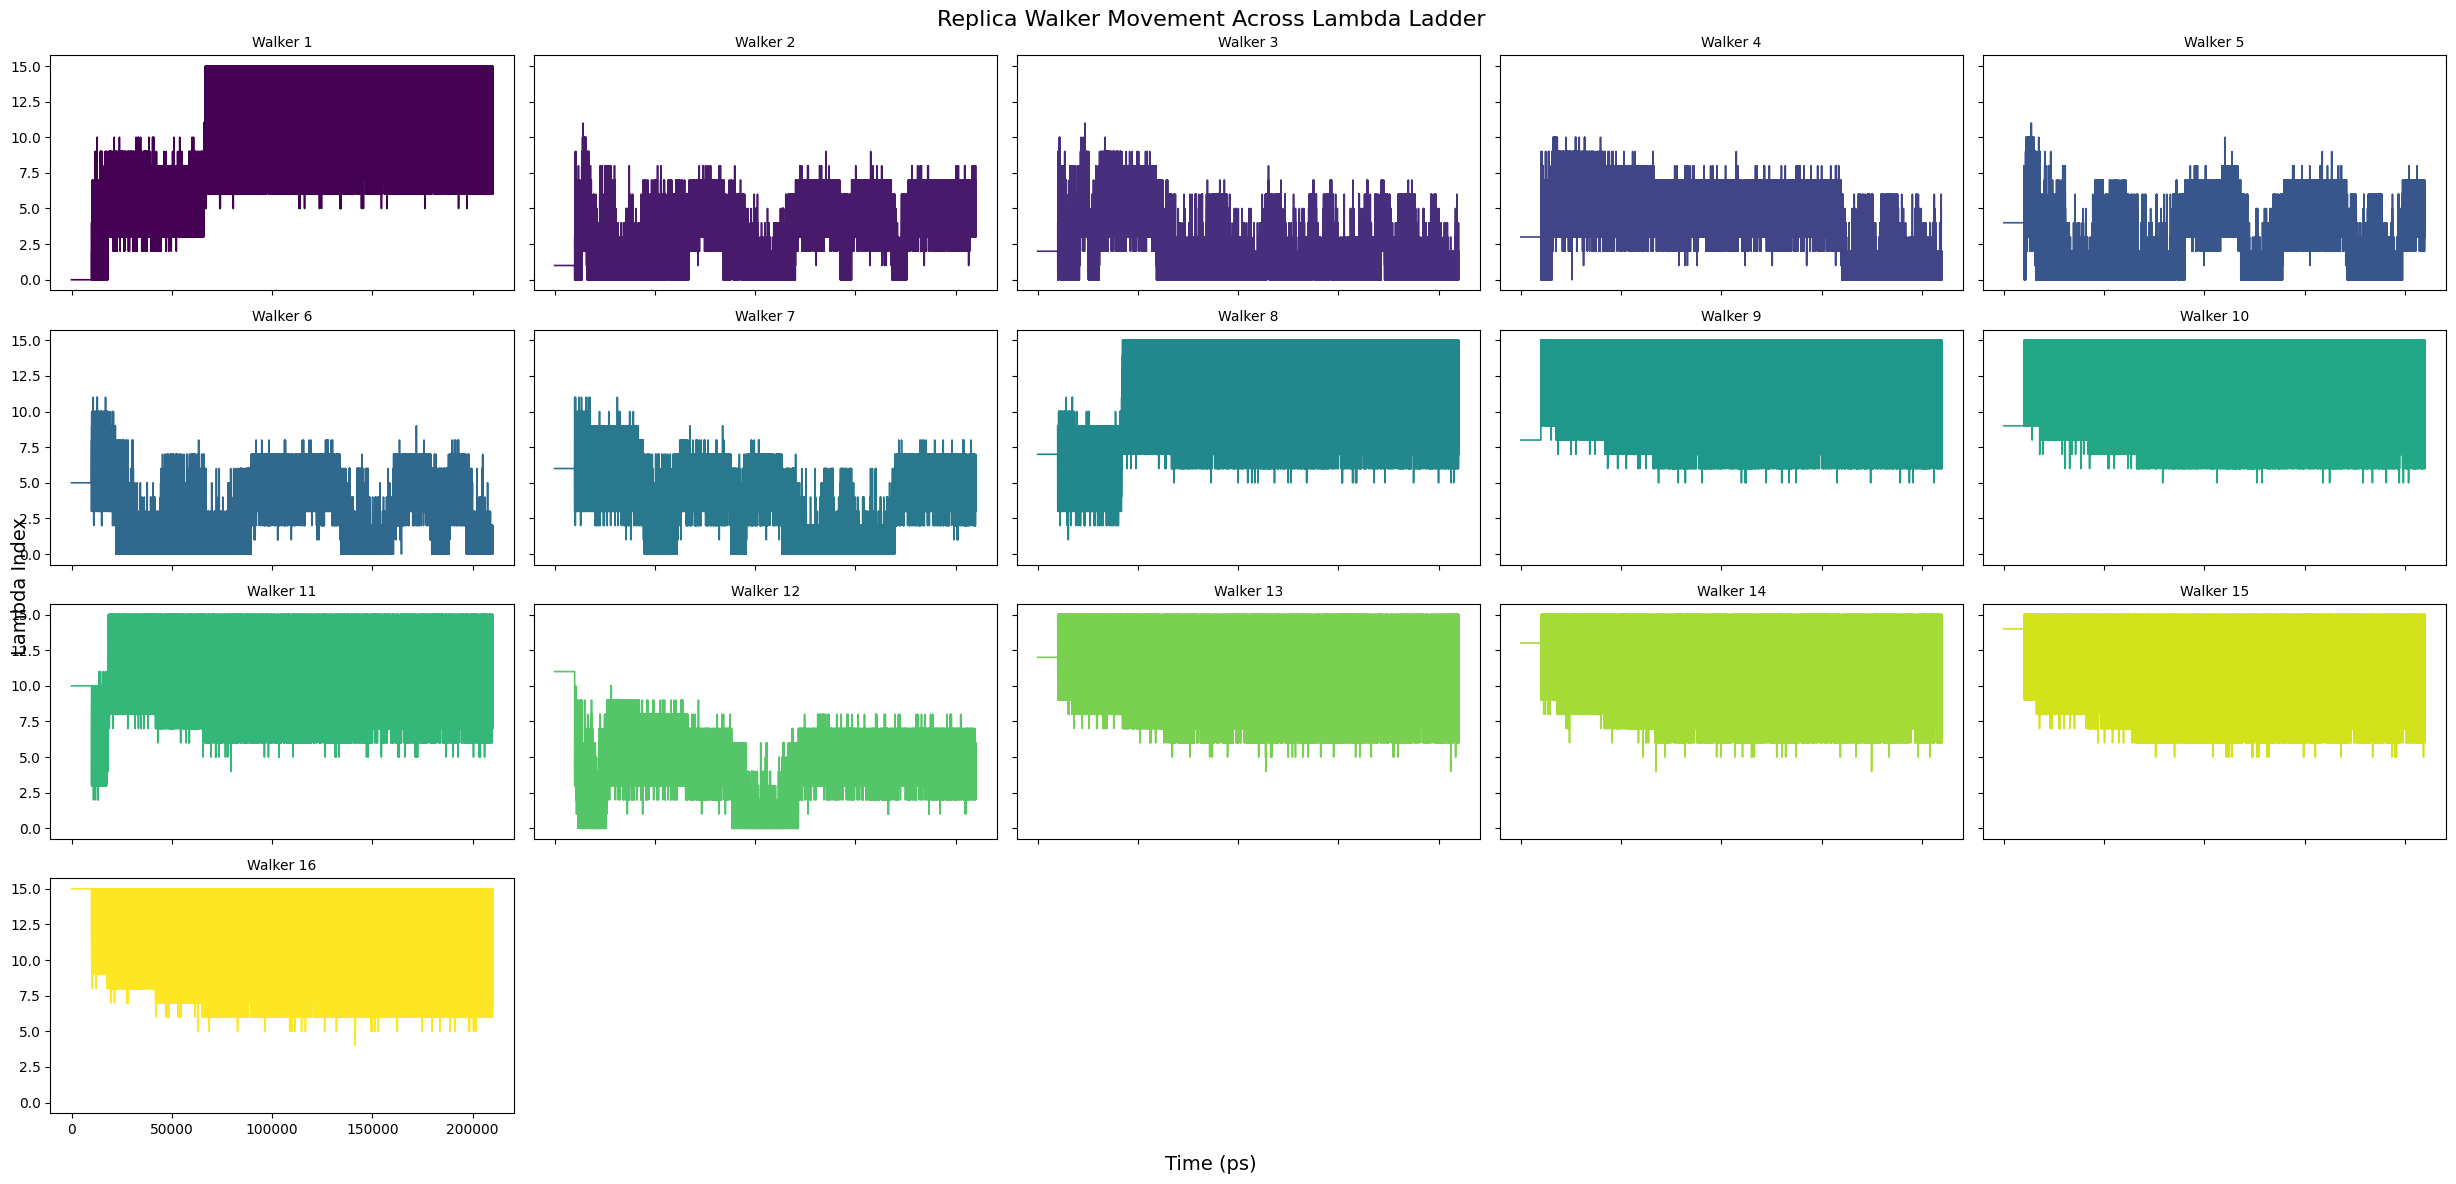

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Load data
rep = np.loadtxt("replica_temp.xvg", comments=["#", "@"])
time = rep[:, 0]
n_walkers = rep.shape[1] - 1

# Grid layout: 5 per row
ncols = 5
nrows = math.ceil(n_walkers / ncols)

# Colormap for gradient
cmap = plt.get_cmap("viridis")
colors = cmap(np.linspace(0, 1, n_walkers))

# Create subplots with shared axes
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5*ncols, 3*nrows),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

# Plot each walker with gradient color
for i in range(n_walkers):
    ax = axes[i]
    ax.plot(time, rep[:, i+1], linewidth=1.2, color=colors[i])
    ax.set_title(f"Walker {i+1}", fontsize=10)

# Remove unused panels
for j in range(n_walkers, len(axes)):
    fig.delaxes(axes[j])

# Global labels
fig.supxlabel("Time (ps)", fontsize=14)
fig.supylabel("Lambda Index", fontsize=14)
fig.suptitle("Replica Walker Movement Across Lambda Ladder", fontsize=16)

plt.tight_layout()
plt.show()


### **Result**

Walkers **2 to 7** remain confined within the lowest temperature range   (**100–110 K**, corresponding to replicas **0–5** respectively) and **do not diffuse** into the  higher-energy, unfolded region.
This indicates that these walkers are **effectively  trapped in the native ↔ intermediate regime**, without successful exchange into the unfolded basin.


Walker 1,8 and 11 shows **smooth and efficient transitions** across the ensemble, moving from folded → intermediate → unfolded states as seen in the visualization below.

# Summary of Figure above 

Walker **1,8,11** successfully escapes into the unfolded region at differnt time points. It begins in the native basin, transitions to the intermediate state, and then continues into the unfolded ensemble, showing a complete N → I → U progression over the course of the trajectory.

________________________________

### 🔁 Demuxed Trajectory Reconstruction  
Combine all replica trajectories using **trjcat with the demux file** to generate temperature-ordered (`T__trajout.xtc`) trajectories for further analysis.

### 🔁 REMD Exchange Logic

Walkers run MD → try to swap → continue at new temperatures:

🔴 T4: ④ →↔→ ③  
🟠 T3: ③ →↔→ ④  
🟢 T2: ② →↔→ ②  
🔵 T1: ① →✖️→ ①  

Successful swaps (↔) move walkers up/down the ladder, failed swaps (✖️) keep them in place.

**Result:** trajectories get *scrambled* 🔀 —  
demux + trjcat rebuild the *true* temperature-ordered paths 📈✨.


In [23]:
#Demuxed trajectories 
import subprocess

# Directories for your 16 replicas:
dirs = ["100", "102", "104", "106", "106.5", "107","107.5", "108","108.5", "109", "109.5", "110", "112", "114", "116", "118"]

# Construct the trjcat command with temperature-specific output names
cmd = (
    "gmx_mpi trjcat -cat "
    + "-f " + " ".join([f"{d}/traj_comp.xtc" for d in dirs])
    + " -demux replica_index.xvg "
    + "-o " + " ".join([f"{t}__trajout.xtc" for t in dirs])
)

print("Running:", cmd)
subprocess.run(cmd, shell=True)


Running: gmx_mpi trjcat -cat -f 100/traj_comp.xtc 102/traj_comp.xtc 104/traj_comp.xtc 106/traj_comp.xtc 106.5/traj_comp.xtc 107/traj_comp.xtc 107.5/traj_comp.xtc 108/traj_comp.xtc 108.5/traj_comp.xtc 109/traj_comp.xtc 109.5/traj_comp.xtc 110/traj_comp.xtc 112/traj_comp.xtc 114/traj_comp.xtc 116/traj_comp.xtc 118/traj_comp.xtc -demux replica_index.xvg -o 100__trajout.xtc 102__trajout.xtc 104__trajout.xtc 106__trajout.xtc 106.5__trajout.xtc 107__trajout.xtc 107.5__trajout.xtc 108__trajout.xtc 108.5__trajout.xtc 109__trajout.xtc 109.5__trajout.xtc 110__trajout.xtc 112__trajout.xtc 114__trajout.xtc 116__trajout.xtc 118__trajout.xtc


/bin/sh: ml: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `ml'
/bin/sh: find_port: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `find_port'
/bin/sh: which: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `which'
/bin/sh: create_passwd: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `create_passwd'
/bin/sh: random_number: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `random_number'
/bin/sh: module: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `module'
/bin/sh: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `setup_accre_software_stack'
/bin/sh: wait_until_port_used: line 1: syntax error: unexpected end of file
/bin/sh: error impor

Note that major changes are planned in future for trjcat, to improve usability and utility.Read 16 sets of 500002 points, dt = 0.419998



CompletedProcess(args='gmx_mpi trjcat -cat -f 100/traj_comp.xtc 102/traj_comp.xtc 104/traj_comp.xtc 106/traj_comp.xtc 106.5/traj_comp.xtc 107/traj_comp.xtc 107.5/traj_comp.xtc 108/traj_comp.xtc 108.5/traj_comp.xtc 109/traj_comp.xtc 109.5/traj_comp.xtc 110/traj_comp.xtc 112/traj_comp.xtc 114/traj_comp.xtc 116/traj_comp.xtc 118/traj_comp.xtc -demux replica_index.xvg -o 100__trajout.xtc 102__trajout.xtc 104__trajout.xtc 106__trajout.xtc 106.5__trajout.xtc 107__trajout.xtc 107.5__trajout.xtc 108__trajout.xtc 108.5__trajout.xtc 109__trajout.xtc 109.5__trajout.xtc 110__trajout.xtc 112__trajout.xtc 114__trajout.xtc 116__trajout.xtc 118__trajout.xtc', returncode=0)

### 🔎 Extracting Native Contacts  
Pull the **[ pairs ]** section from the topology and save only the clean contact list (no headers or comments) into `file.cont` for further analysis.

Note: The contact-based analysis (from native contacts → WHAM → free-energy reconstruction) follows the workflow adapted from the SMOG2 tutorial: https://github.com/smog-server/SMOG2_tutorial

In [24]:
%%bash
# Extract the [ pairs ] section but skip the header/comment lines
awk '
  /^\s*\[\s*pairs\s*\]/{flag=1; next}
  /^\s*\[/{flag=0}
  flag && $1 !~ /^;/ {print}
' 6ONJ-AA.top > file.cont

echo "✅ file.cont created (no header line)"
head -n 10 file.cont

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

✅ file.cont created (no header line)
1	34	1	 2.747874117e-02 3.560894371e-04
1	35	1	 2.882003776e-02 3.917008513e-04
4	29	1	 1.696627064e-03 1.357494896e-06
4	33	1	 3.849405972e-03 6.987999352e-06
4	34	1	 1.840124421e-03 1.596834116e-06
4	35	1	 3.454643797e-03 5.628231775e-06
4	1694	1	 2.960272911e-02 4.132652862e-04
5	29	1	 3.972156851e-02 7.440775536e-04
11	1694	1	 4.071967593e-03 7.819411173e-06
13	37	1	 7.785450219e-04 2.858465065e-07


### 🧮 Contact Map Computation  
Loop through each temperature folder and run the Python contact calculator to generate **contacts-AA-\<T\>.dat** files, logging all output to `out-contacts-AA.dat` for easy tracking.

In [25]:
%%bash
# List of temperatures (change if you have a different set)
temperatures="100 102 104 106 106.5 107 107.5 108 108.5 109 109.5 110 112 114 116 118"

# Remove old log
rm -f out-contacts-AA.dat

for T in $temperatures; do
  echo "🔍 Computing contacts for T=$T ..."
  
  (
    cd $T
    python3 ../../contacts-python/src/contacts_chunk.py \
        AA ../6ONJ-AA-box.gro \
        traj_comp.xtc ../file.cont \
        contacts-AA-${T}.dat
  ) &>> out-contacts-AA.dat

done

echo "🎯 All contacts computed successfully."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🔍 Computing contacts for T=100 ...
🔍 Computing contacts for T=102 ...
🔍 Computing contacts for T=104 ...
🔍 Computing contacts for T=106 ...
🔍 Computing contacts for T=106.5 ...
🔍 Computing contacts for T=107 ...
🔍 Computing contacts for T=107.5 ...
🔍 Computing contacts for T=108 ...
🔍 Computing contacts for T=108.5 ...
🔍 Computing contacts for T=109 ...
🔍 Computing contacts for T=109.5 ...
🔍 Computing contacts for T=110 ...
🔍 Computing contacts for T=112 ...
🔍 Computing contacts for T=114 ...
🔍 Computing contacts for T=116 ...
🔍 Computing contacts for T=118 ...
🎯 All contacts computed successfully.


### 
🧹 Energy Cleanup  
For each temperature folder, automatically detect the correct energy file, remove GROMACS headers, and extract clean **timestep** and **energy** arrays for downstream analysis.


In [26]:
%%bash

temps="100 102 104 106 106.5 107 107.5 108 108.5 109 109.5 110 112 114 116 118"

for T in $temps; do
  cd "$T" || continue

  # pick energy.xvg or potential.xvg
  if   [ -f energy.xvg    ]; then XVG=energy.xvg
  elif [ -f potential.xvg ]; then XVG=potential.xvg
  else
    echo "⚠️ No energy file found in $T"; cd ..; continue
  fi

  # Strip headers (@ or #) and split into two clean files
  grep -v '^[@#]' "$XVG" | awk '{print $1}' > "timestep-$T.dat"
  grep -v '^[@#]' "$XVG" | awk '{print $2}' > energy.dat

  echo "✅ $T cleaned: $(wc -l < energy.dat) energy points"
  cd ..
done

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

✅ 100 cleaned: 210001 energy points
✅ 102 cleaned: 210001 energy points
✅ 104 cleaned: 210001 energy points
✅ 106 cleaned: 210001 energy points
✅ 106.5 cleaned: 210001 energy points
✅ 107 cleaned: 210001 energy points
✅ 107.5 cleaned: 210001 energy points
✅ 108 cleaned: 210001 energy points
✅ 108.5 cleaned: 210001 energy points
✅ 109 cleaned: 210001 energy points
✅ 109.5 cleaned: 210001 energy points
✅ 110 cleaned: 210001 energy points
✅ 112 cleaned: 210001 energy points
✅ 114 cleaned: 210001 energy points
✅ 116 cleaned: 210001 energy points
✅ 118 cleaned: 210001 energy points


### 🔗 Build Energy–Contact Files  
Combine each folder’s **energy.dat** and **contacts-AA-\<T\>.dat** into a unified `e-Q.dat` file, pairing potential energy with native contacts for every frame.


In [27]:
%%bash
echo "🔧 Creating e-Q.dat files (energy + contacts)..."

# Loop through each subdirectory (80, 90, ...)
for dir in */; do
  T="${dir%/}"  # remove trailing slash
  echo "📂 Processing $T ..."

  # Check if input files exist before pasting
  if [[ -f "$T/energy.dat" && -f "$T/contacts-AA-$T.dat" ]]; then
    paste -d " " "$T/energy.dat" "$T/contacts-AA-$T.dat" > "$T/e-Q.dat"
    echo "✅ $T/e-Q.dat created ($(wc -l < "$T/e-Q.dat") frames)"
  else
    echo "❌ Skipping $T — missing energy.dat or contacts-AA-$T.dat"
  fi

  sleep 0.2
done

echo "🎯 All available e-Q.dat files have been generated."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🔧 Creating e-Q.dat files (energy + contacts)...
📂 Processing 100 ...
✅ 100/e-Q.dat created (210001 frames)
📂 Processing 102 ...
✅ 102/e-Q.dat created (210001 frames)
📂 Processing 104 ...
✅ 104/e-Q.dat created (210001 frames)
📂 Processing 106 ...
✅ 106/e-Q.dat created (210001 frames)
📂 Processing 106.5 ...
✅ 106.5/e-Q.dat created (210001 frames)
📂 Processing 107 ...
✅ 107/e-Q.dat created (210001 frames)
📂 Processing 107.5 ...
✅ 107.5/e-Q.dat created (210001 frames)
📂 Processing 108 ...
✅ 108/e-Q.dat created (210001 frames)
📂 Processing 108.5 ...
✅ 108.5/e-Q.dat created (210001 frames)
📂 Processing 109 ...
✅ 109/e-Q.dat created (210001 frames)
📂 Processing 109.5 ...
✅ 109.5/e-Q.dat created (210001 frames)
📂 Processing 110 ...
✅ 110/e-Q.dat created (210001 frames)
📂 Processing 112 ...
✅ 112/e-Q.dat created (210001 frames)
📂 Processing 114 ...
✅ 114/e-Q.dat created (210001 frames)
📂 Processing 116 ...
✅ 116/e-Q.dat created (210001 frames)
📂 Processing 118 ...
✅ 118/e-Q.dat created (210001 

### 🔎 Pre-WHAM Range Inspection  
Use the output from this scan to guide WHAM settings — the observed **energy** and **Q** ranges determine the appropriate `start`, `step`, and `numBins` values in the next configuration step.


In [29]:
import numpy as np
import glob
import os

files = sorted(glob.glob("*/e-Q.dat"), key=lambda x: float(x.split("/")[-2]))

if not files:
    raise RuntimeError("No e-Q.dat files found!")

print(f"{'Temp(K)':>7}  {'E_min':>12}  {'E_max':>12}  {'Q_min':>10}  {'Q_max':>10}")
print("-"*60)

for f in files:
    T = os.path.basename(os.path.dirname(f))
    try:
        data = np.loadtxt(f, comments="#")
    except Exception as e:
        print(f"⚠️ {T}: Failed to read ({e})")
        continue

    if data.ndim != 2 or data.shape[1] < 2:
        print(f"⚠️ {T}: Malformed data, skipping")
        continue

    E = data[:, 0]  # energy
    Q = data[:, 1]  # contacts

    print(f"{T:>7}  {E.min():12.3f}  {E.max():12.3f}  {Q.min():10.3f}  {Q.max():10.3f}")


Temp(K)         E_min         E_max       Q_min       Q_max
------------------------------------------------------------
    100     -1437.908      2111.597    1891.000    2739.000
    102     -1437.908      2262.971    1575.000    2739.000
    104     -1437.908      2485.030    1388.000    2739.000
    106     -1437.909      2720.697    1048.000    2739.000
  106.5     -1437.909      3058.278     196.000    2739.000
    107     -1437.909      3179.378     123.000    2739.000
  107.5     -1437.909      3273.077     104.000    2739.000
    108     -1437.909      3339.350      98.000    2739.000
  108.5     -1437.909      3341.365      76.000    2739.000
    109     -1437.909      3350.506      83.000    2739.000
  109.5     -1437.908      3365.289      83.000    2739.000
    110     -1437.909      3396.722      87.000    2739.000
    112     -1437.909      3440.673      75.000    2739.000
    114     -1437.909      3523.398      71.000    2739.000
    116     -1437.908      3560.462    

### 🔎 Parameter Check for WHAM  
From the scan above, **E_min ≈ –1438 kJ/mol**, so setting:

- **`start -1500`** → safely below the lowest observed energy  
- **`numBins 2800`** → wide enough to cover the full energy span up to ~3600  

This ensures the WHAM histogram includes all sampled states without clipping.


### 📝 WHAM Configuration Setup  
Create a clean `config_wham.txt` file for 2D WHAM analysis, defining histogram bins, input trajectory files, and all thermodynamic outputs (DOS, Cv, free energy, coordinate scans).


In [30]:
%%bash
mkdir -p ../Wham/6ONJ
cd ../Wham/6ONJ

cat > config_wham.txt <<'EOF'
kB 0.008314 # Boltzmann constant
tolerance 0.00001 # convergence criterion
overwriting # allow overwrite of previous outputs
threads 6   # use 6 cores

##### define internal histograming #####
numDimensions 2 # columns: Potential_energy and Q

# Energy histogram bins (excluding outliers from 320/350/360/370 K)
numBins 600
start -1500       # slightly below min energy (-1438.070)
step 20           # bin width chosen to cover ~11000 kJ/mol max safely

# Q histogram bins
numBins 2800
start 0
step 1

##### trajectory files (2 columns: Potential_energy and Q)
numFiles 16
name /work/6ONJ/100/e-Q.dat temp 100
name /work/6ONJ/102/e-Q.dat temp 102
name /work/6ONJ/104/e-Q.dat temp 104
name /work/6ONJ/106/e-Q.dat temp 106
name /work/6ONJ/106.5/e-Q.dat temp 106.5
name /work/6ONJ/107/e-Q.dat temp 107
name /work/6ONJ/107.5/e-Q.dat temp 107.5
name /work/6ONJ/108/e-Q.dat temp 108
name /work/6ONJ/108.5/e-Q.dat temp 108.5
name /work/6ONJ/109/e-Q.dat temp 109
name /work/6ONJ/109.5/e-Q.dat temp 109.5
name /work/6ONJ/110/e-Q.dat temp 110
name /work/6ONJ/112/e-Q.dat temp 112
name /work/6ONJ/114/e-Q.dat temp 114
name /work/6ONJ/116/e-Q.dat temp 116
name /work/6ONJ/118/e-Q.dat temp 118

run_wham
dosFile dos.dat

run_cv
startT 100
deltaT 0.2
ntemps 100
run_cv_out cv.dat

run_free
startTF 100
deltaTF 0.2
ntempsF 100
run_free_out free/

run_coord
startTC 100
deltaTC 0.2
ntempsC 100
run_coord_out coord.dat
EOF

echo "✅ Cleaned config_wham.txt created in $(pwd)"


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

✅ Cleaned config_wham.txt created in /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/Wham/6ONJ


### 🚀 Running WHAM  
Execute **WHAM.jar** inside the Apptainer container, using the edited paths in `config_wham.txt` (mapped to `/work`) to perform the full multi-temperature WHAM analysis.


In [54]:
%%bash
cd ../Wham/6ONJ
#Here we ask the apptainer to execute at .. which we call the /work directory hence we had to edit file names above in the WHAM config file

echo "🚀 Running WHAM.jar with config_wham.txt ..."
apptainer exec --bind /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/:/work \
  ~/smog2.sif java -Xmx1g -jar /opt/smog2/src/tools/WHAM.jar \
  --config /work/Wham/6ONJ/config_wham.txt


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🚀 Running WHAM.jar with config_wham.txt ...
Parsing configuration file: /work/Wham/6ONJ/config_wham.txt

Listing files and temperatures
/work/6ONJ/100/e-Q.dat 100.0
/work/6ONJ/102/e-Q.dat 102.0
/work/6ONJ/104/e-Q.dat 104.0
/work/6ONJ/106/e-Q.dat 106.0
/work/6ONJ/106.5/e-Q.dat 106.5
/work/6ONJ/107/e-Q.dat 107.0
/work/6ONJ/107.5/e-Q.dat 107.5
/work/6ONJ/108/e-Q.dat 108.0
/work/6ONJ/108.5/e-Q.dat 108.5
/work/6ONJ/109/e-Q.dat 109.0
/work/6ONJ/109.5/e-Q.dat 109.5
/work/6ONJ/110/e-Q.dat 110.0
/work/6ONJ/112/e-Q.dat 112.0
/work/6ONJ/114/e-Q.dat 114.0
/work/6ONJ/116/e-Q.dat 116.0
/work/6ONJ/118/e-Q.dat 118.0

Scaling temperatures * kB
Running high precision WHAM calculation.
Reading in histograms.
/work/6ONJ/100/e-Q.dat 210001 lines.
/work/6ONJ/102/e-Q.dat 210001 lines.
/work/6ONJ/104/e-Q.dat 210001 lines.
/work/6ONJ/106/e-Q.dat 210001 lines.
/work/6ONJ/106.5/e-Q.dat 210001 lines.
/work/6ONJ/107/e-Q.dat 210001 lines.
/work/6ONJ/107.5/e-Q.dat 210001 lines.
/work/6ONJ/108/e-Q.dat 210001 lines.
/

### 🌡️ Specific Heat Curve  
Plot the **Cv vs. Temperature** profile from WHAM to identify thermal transitions — with the peak near **107.8 K** marking the intermeidate state and the one near 110 marking the unfolded state 

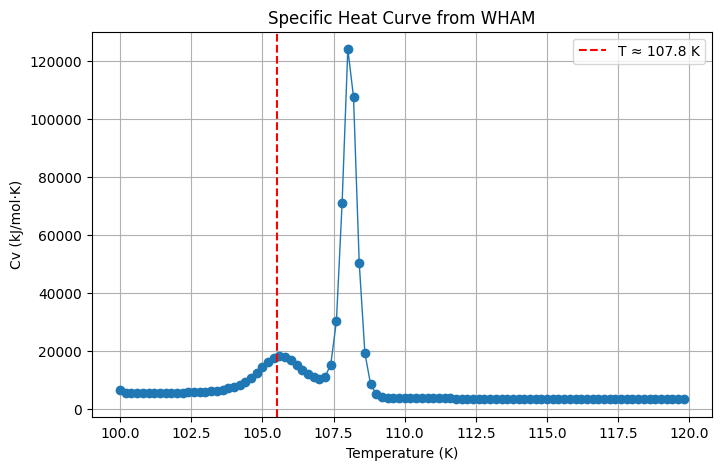

In [55]:
import numpy as np
import matplotlib.pyplot as plt

cv = np.loadtxt("../Wham/6ONJ/cv.dat")
T, Cv = cv[:,0], cv[:,1]

plt.figure(figsize=(8,5))
plt.plot(T, Cv, marker="o", lw=1)
plt.axvline(105.5, color="r", ls="--", label="T ≈ 107.8 K")
plt.xlabel("Temperature (K)")
plt.ylabel("Cv (kJ/mol·K)")
plt.title("Specific Heat Curve from WHAM")
plt.legend()
plt.grid()
plt.show()


### 🔍 Interpretation of the Specific Heat Curve

The WHAM-derived specific heat profile exhibits two thermodynamically meaningful features.  
A subtle shoulder appears near **~105.5 K** (indicated by the vertical dashed line), marking an **increase in energy fluctuations** associated with the onset of the **native → intermediate** transition. In structure-based (SMOG) models, such precursors in \( C_V(T) \) typically reflect the system entering a partially unfolded, metastable basin with measurable thermodynamic weight.

A much sharper and more pronounced peak is observed at **~108 K**, representing the temperature at which the system undergoes a **cooperative transition into the unfolded ensemble**. The magnitude and narrowness of this peak indicate a large increase in heat capacity, consistent with a significant reorganization of the energy landscape—characteristic of a major unfolding event.

The presence of both a **distinct pre-transition shoulder** and a **dominant unfolding peak** confirms that the SMOG model resolves a **thermodynamically stable intermediate state** rather than a transient kinetic fluctuation. Together, these features delineate a clear **N → I → U** progression, with each basin separated by measurable changes in energy variance and heat capacity.

**Note that the separation between the intermediate and the unfolded heat curve peaks is a lot more than in 6ONJ than 3PRG.** 
May suggest that its more energetically isolated from the unfolded state in 6ONJ

### 📉 Free-Energy Profiles 

Found 100 free-energy profiles.


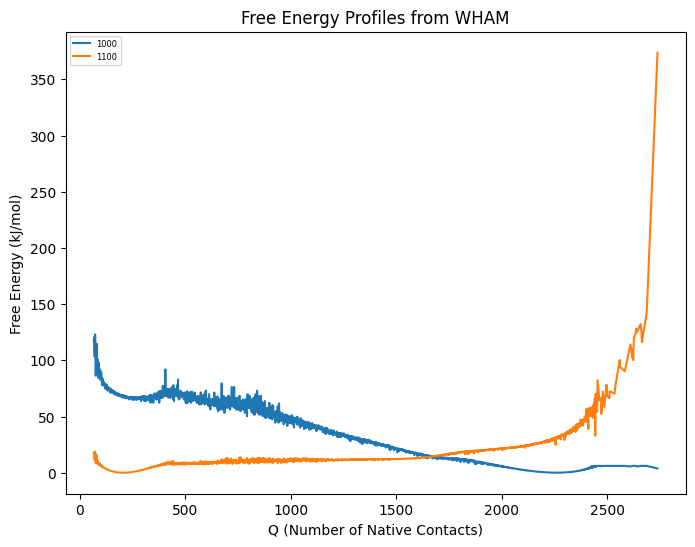

In [56]:
#free energies are not smooth but this is not bad for 1100
import numpy as np
import glob
import matplotlib.pyplot as plt

free_files = sorted(glob.glob("../Wham/6ONJ/free/*"))
print(f"Found {len(free_files)} free-energy profiles.")

plt.figure(figsize=(8,6))
for f in free_files[::50]:  # plot every 50th to avoid clutter
    data = np.loadtxt(f)
    Q, F = data[:,0], data[:,1]
    plt.plot(Q, F, label=f.split('/')[-1])

plt.xlabel("Q (Number of Native Contacts)")
plt.ylabel("Free Energy (kJ/mol)")
plt.title("Free Energy Profiles from WHAM")
plt.legend(fontsize=6)
plt.show()

### 🔍 Understanding the WHAM Free-Energy Curves

The WHAM setup reconstructs free-energy surfaces over a continuous temperature range from 100 K upward in 0.2 K increments, generating 100 individual free-energy profiles, and the two curves shown arise simply because the plotting script subsampled this directory (`free_files[::50]`) and therefore selected one profile near 100 K and another near 110 K; this is not due to using two CVs, since WHAM was run with a single reaction coordinate (Q) together with potential energy as a second dimension for histogramming. 

### 📈 What the Q-Axis Represents

In this SMOG/WHAM representation, the Q-axis corresponds to internal histogram bin indices rather than the absolute number of native contacts, which is why the values fall in the 100000–110000 range, and lower Q-bin values represent more native-like structures while higher values reflect progressively unfolded states.

### 🧬 Interpreting the Two Curves

The free-energy curve (blue) 100 K displays a minima at 2300 and a lighter one around 1700 and the unfolded basin near 0, consistent with the system remaining in the native basin as well as showing an intermediate basin, whereas the curve for 110 K (orange) shows the unfolded basin flattened ( Q near 0) and folded regions (above 1000 contacts) with increasing free energy suggesting the system rolls into unfolded states.
*********************************************

### 🌡️ Free Energy Landscape at **108 K** 

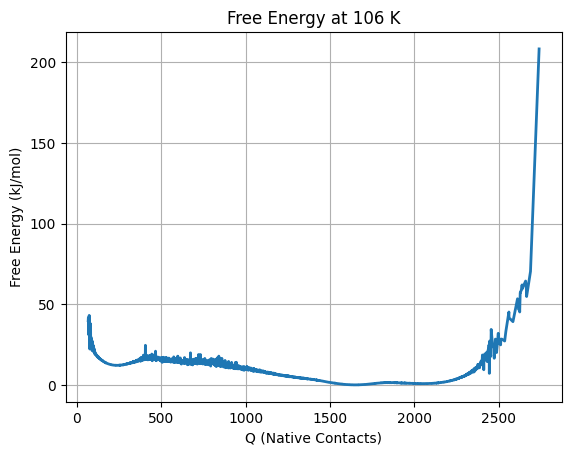

In [57]:
import numpy as np, glob, matplotlib.pyplot as plt

# Find the file for 106 K
files = glob.glob("../Wham/6ONJ/free/*106*")
if not files: raise FileNotFoundError("No 106 K free-energy file found.")
data = np.loadtxt(files[0])

plt.plot(data[:,0], data[:,1], lw=2)
plt.xlabel("Q (Native Contacts)")
plt.ylabel("Free Energy (kJ/mol)")
plt.title("Free Energy at 106 K")
plt.grid()
plt.show()


### 🔍 Interpretation of the Free-Energy Profile at 106 K

#### **Emergence of the Intermediate as the Dominant Basin**
At **106 K**, the folding landscape undergoes a significant reorganization: the global minimum in free energy shifts from the high-Q native region (2300 contacts) to a new minimum centered around **Q ≈ 1600**, marking the thermodynamic stabilization of the **intermediate** state. This shift indicates that native contacts have been partially disrupted and that the protein now prefers athe intermediate conformation. Also note the intermedaite has a deeper minima than in 3PRG and is well defined. The increasing contacts may suggest that the intermediate is a lot more stable here. 

#### **Destabilization of the Native State**
The native basin at high Q (Q ~ 2300) is still present but lies clearly higher in free energy compared to the intermediate. This elevation reflects a loss of stability in the fully folded structure as temperature approaches the transition point. Although the native state remains structurally accessible, it no longer represents the dominant ensemble, confirming that the system has moved past the purely native regime observed at 106 K.

#### **Onset of Access to Lower-Q States**
While unfolded-like conformations at very low Q values (below Q ≈ 300) are still energetically costly, the free-energy slope toward this region becomes smoother and less steep than at lower temperatures. The system is beginning to sample broader structural diversity as the intermediate takes over as the principal thermodynamic population.

#### **Overall Insight**
The free-energy profile at 106 K demonstrates that this temperature marks the **onset of intermediate-state dominance**, where the protein preferentially occupies a partially folded ensemble with retained structural elements but reduced native contact density. 
____________________

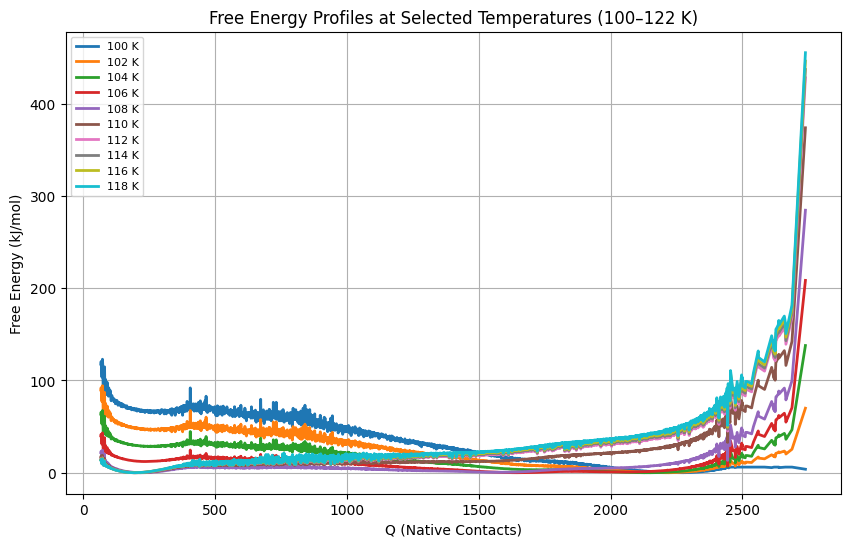

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import glob

# Temperatures to plot
temps = list(range(100, 120, 2))  # 100, 102, 104, ..., 122

plt.figure(figsize=(10, 6))

for T in temps:
    # match WHAM free file for this temperature
    pattern = f"../Wham/6ONJ/free/*{T}*"
    files = glob.glob(pattern)
    
    if not files:
        print(f"⚠️ No WHAM free-energy file found for {T} K")
        continue
    
    freefile = files[0]
    data = np.loadtxt(freefile)
    
    Q = data[:, 0]
    F = data[:, 1]
    
    plt.plot(Q, F, lw=2, label=f"{T} K")

plt.xlabel("Q (Native Contacts)")
plt.ylabel("Free Energy (kJ/mol)")
plt.title("Free Energy Profiles at Selected Temperatures (100–122 K)")
plt.legend(fontsize=8)
plt.grid(True)
plt.show()


### 🔥 Global Overview

### 🔵 Native Basin (High Q ≈ 2300–2600)
At low temperatures (100–106 K), the free-energy minimum sits at high Q,
meaning the protein is fully native. The well is deep and narrow, so a rolling
ball would simply fall into this high-Q valley and stay there. As temperature
rises toward 106 K, the native well flattens and widens, showing that the
protein begins to fluctuate but still remains folded.

### 🟣 Intermediate Basin (Mid Q ≈ 1400–1800)
At 108–110 K, the landscape reorganizes and the lowest free energy shifts to
Q ≈ 1500. This marks the stabilization of the intermediate state. In the ball
analogy, the deepest well is now in the middle, so the ball naturally settles
there instead of the native region. The native basin rises in free energy,
becoming a higher plateau, confirming that the system prefers partially folded
structures at these temperatures.

### 🟡 Low-Q / Unfolded Region (Q < 500)
At low temperatures this region is a steep uphill wall, so the ball cannot enter
it and unfolded conformations are excluded. As temperature increases past
110–112 K, the slope into the low-Q region becomes gentler, allowing the ball to
roll further left. By 114–116 K, the landscape toward low Q is noticeably
flattened, indicating early stages of unfolding, although a fully unfolded basin
has not yet formed.

### 🔍 Overall Picture
Across temperatures, the landscape shifts smoothly from a native-dominated well,
to a mid-Q intermediate minimum, and finally toward accessible low-Q regions.
In the ball analogy, the “lowest point” of the terrain slides from high Q → mid
Q → lower Q as temperature increases, capturing the full **N → I → partial-U**
transition in the SMOG folding model.


### 📥 Reading All `e-Q.dat` Files into DataFrames

First we define a helper (`read_eQ`) to load each `e-Q.dat` file into a clean Pandas DataFrame with **Potential** and **Q** columns.  
Then we loop through all temperature folders (**100 → 118 K**) and collect the data into `all_frames` for combined analysis. 🚀

In [42]:
import pandas as pd, os

def read_eQ(path):
    """Read energy + Q from e-Q.dat (two columns: energy, contacts)."""
    fname = os.path.join(path, "e-Q.dat")
    if not os.path.exists(fname):
        raise FileNotFoundError(f"{fname} not found")
    df = pd.read_csv(fname, sep=r'\s+', comment='#', header=None, engine='python')
    df = df.rename(columns={0:"Potential", 1:"Q"})
    return df.dropna().reset_index(drop=True)


In [43]:
all_frames = []
temps = [100, 102, 104, 106, 106.5, 107, 107.5, 108, 108.5, 109, 109.5, 110, 112, 114, 116, 118]

for folder in temps:   # 100, 102, 104, ..., 118
    folder = str(folder)
    fname = os.path.join(folder, "e-Q.dat")

    if os.path.exists(fname):
        print("Reading:", fname)
        df = read_eQ(folder)
        all_frames.append(df)
    else:
        print("Skipping (not found):", fname)


Reading: 100/e-Q.dat
Reading: 102/e-Q.dat
Reading: 104/e-Q.dat
Reading: 106/e-Q.dat
Reading: 106.5/e-Q.dat
Reading: 107/e-Q.dat
Reading: 107.5/e-Q.dat
Reading: 108/e-Q.dat
Reading: 108.5/e-Q.dat
Reading: 109/e-Q.dat
Reading: 109.5/e-Q.dat
Reading: 110/e-Q.dat
Reading: 112/e-Q.dat
Reading: 114/e-Q.dat
Reading: 116/e-Q.dat
Reading: 118/e-Q.dat


### 📊 Combined Q-Distribution Across All Replicas  
After loading all `e-Q.dat` files, we merge them into one DataFrame and plot the overall **distribution of native contacts (Q)**.  
This gives a quick global view of how the system samples **unfolded → intermediate → folded** states across the full temperature ladder. 🔥❄️


In [44]:
frames = pd.concat(all_frames, ignore_index=True)

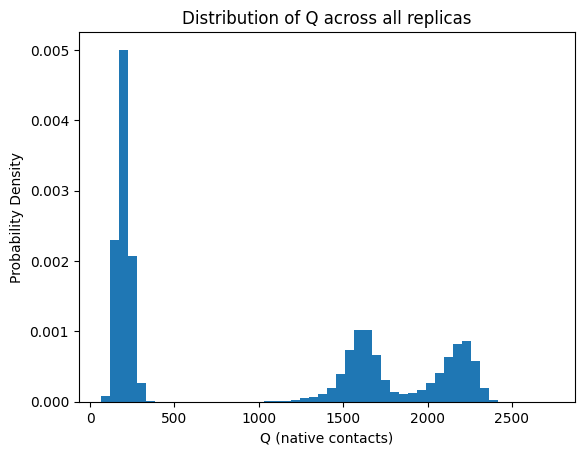

In [49]:
import matplotlib.pyplot as plt
plt.hist(frames["Q"], bins=50, density=True)
plt.xlabel("Q (native contacts)")
plt.ylabel("Probability Density")
plt.title("Distribution of Q across all replicas")
plt.show()


### 🔍 Results from plot above - Global Q-Distribution Across All Temperatures  
This combined histogram shows **native intermediate and unfolded conformations sampled across all replicas**.  
The **left peak (~0–300)** corresponds to unfolded states, the **broad middle region (~1200–1700)** captures intermediates,  
and the **right peak (~1900–2400)** reflects folded conformations.  
Together, these clusters confirm that the replica-exchange ladder successfully spans the full folding landscape. 

************************************************

# **The cells from below are not used in the publication; these are just for explorative data analysis. You can play around if necessary !** 

### 🔄 NEXT CELL: Reweighting Replica-Exchange Data to a Target Temperature

This cell performs **Boltzmann reweighting** of all replicas (100–118 K) to estimate the  
**native, intermediate, and unfolded state populations** at a chosen temperature (e.g., **110 K**).

**What this cell does:**
- 📥 **Loads all e–Q.dat files** (Potential, Q) from each replica.
- 📊 **Defines structural states** using Q ranges (unfolded / intermediate / native).
- 🔢 **Computes statistical weights** for each frame so they correspond to a **target temperature**.
- 🧮 **Reports reweighted populations** of all states at that temperature.
- 🌡️ **Prints raw populations per replica** to visualize how sampling shifts with temperature.
- 🧭 **Sweeps over all target temperatures**, giving state populations at every T.

This produces a **thermodynamic map** of your folding landscape, reconstructed from replica-exchange sampling.


In [50]:
import numpy as np
import pandas as pd
import os

# === USER SETTINGS (EDIT FOR NEW RUNS) ===
dirs = ["100", "102", "104", "106", "106.5", "107","107.5", "108","108.5", "109", "109.5", "110", "112", "114", "116", "118"]  # temperature directories
target_T = 110.0          # target temperature for reweighting (K)
kB = 0.008314462618       # kJ/mol/K

# === STATE DEFINITIONS (Q ranges) ===
# You can use None for open-ended ranges
Q_RANGES = {
    "unfolded":    (None,  500),    # Q <= 500
    "intermediate":( 500, 1800),   # 500 < Q <= 1950
    "native":      (1800, None)    # Q > 1950
}

# === Helper: read e-Q.dat (energy + Q) ===
def read_eQ(path):
    fname = os.path.join(path, "e-Q.dat")
    if not os.path.exists(fname):
        raise FileNotFoundError(f"{fname} not found")
    df = pd.read_csv(fname, sep=r'\s+', comment='#', header=None, engine='python')
    df = df.rename(columns={0:"Potential", 1:"Q"})
    return df.dropna().reset_index(drop=True)

# === Load all replicas ===
blocks = []
for d in dirs:
    df = read_eQ(d)
    df["T"] = float(d)
    blocks.append(df)
frames = pd.concat(blocks, ignore_index=True)

# === Compute weights for reweighting to target_T ===
beta_star = 1.0 / (kB * target_T)
beta_k    = 1.0 / (kB * frames["T"].values)
E         = frames["Potential"].values
logw = -(beta_star - beta_k) * E
logw -= np.max(logw)
w = np.exp(logw)
w /= np.sum(w)

Q = frames["Q"].values

# === Classify frames based on Q_RANGES ===
def classify(Q, ranges):
    states = {}
    for name, (low, high) in ranges.items():
        if low is None:
            mask = Q <= high
        elif high is None:
            mask = Q > low
        else:
            mask = (Q > low) & (Q <= high)
        states[name] = mask
    return states

states = classify(Q, Q_RANGES)

# === Print reweighted populations ===
def sci(x): return f"{x:.4e}"

print(f"\n=== Reweighted Populations at {target_T:.1f} K ===")
for name, mask in states.items():
    P = np.sum(w * mask)
    print(f"P({name}) = {sci(P)}")

if np.sum(w * states["unfolded"]) > 0:
    ratio = np.sum(w * states["native"]) / np.sum(w * states["unfolded"])
    print(f"Native/Unfolded ratio = {ratio:.3e}")

# === Per-replica raw populations (no reweighting) ===
print("\n=== Per-Replica Populations (Raw) ===")
temps = sorted(frames["T"].unique())
for T in temps:
    dfT = frames[frames["T"]==T]
    qT = dfT["Q"].values
    sT = classify(qT, Q_RANGES)
    fractions = {name: sT[name].mean() for name in Q_RANGES}
    frac_str = "  ".join(f"{n}={fractions[n]:.3f}" for n in Q_RANGES)
    print(f"{int(T):3d}K  {frac_str}")

# === Sweep reweighting over all target temperatures ===
print("\n=== Reweighted Populations Across Target Temperatures ===")
for Tstar in temps:
    beta_star = 1.0 / (kB * Tstar)
    logw = -(beta_star - beta_k) * E
    logw -= np.max(logw)
    wT = np.exp(logw)
    wT /= np.sum(wT)
    fracs = {name: np.sum(wT * states[name]) for name in Q_RANGES}
    frac_str = "  ".join(f"{n}={fracs[n]:.3f}" for n in Q_RANGES)
    print(f"T*={int(Tstar):3d}K  {frac_str}")



=== Reweighted Populations at 110.0 K ===
P(unfolded) = 4.8293e-53
P(intermediate) = 9.3056e-17
P(native) = 1.0000e+00
Native/Unfolded ratio = 2.071e+52

=== Per-Replica Populations (Raw) ===
100K  unfolded=0.000  intermediate=0.000  native=1.000
102K  unfolded=0.000  intermediate=0.000  native=1.000
104K  unfolded=0.000  intermediate=0.013  native=0.987
106K  unfolded=0.000  intermediate=0.655  native=0.345
106K  unfolded=0.000  intermediate=0.815  native=0.185
107K  unfolded=0.001  intermediate=0.914  native=0.086
107K  unfolded=0.025  intermediate=0.948  native=0.027
108K  unfolded=0.665  intermediate=0.330  native=0.005
108K  unfolded=0.811  intermediate=0.184  native=0.004
109K  unfolded=0.926  intermediate=0.073  native=0.001
109K  unfolded=0.950  intermediate=0.046  native=0.004
110K  unfolded=0.952  intermediate=0.047  native=0.001
112K  unfolded=0.997  intermediate=0.003  native=0.000
114K  unfolded=0.999  intermediate=0.001  native=0.000
116K  unfolded=0.999  intermediate=0.

### 🎯 Reweighting Native vs Intermediate Populations (100–108 K Only)

This cell computes **Boltzmann-reweighted populations** of just two structural states —  
**native** (Q > 1800) and **intermediate** (500 < Q ≤ 1800) — at a chosen target temperature (here **106 K**).  
Unfolded frames (Q < 500) are excluded to sharpen the comparison.

**What this step does:**
- 📥 Loads **only low-temperature replicas** (100–108 K) where native/intermediate states dominate.  
- 🔍 Removes unfolded frames to avoid exaggerating low-Q contributions.  
- 🔢 Applies **Boltzmann reweighting** to estimate populations at **106 K**.  
- 📊 Prints both **reweighted state populations** and **raw per-replica fractions**.

This gives a clean estimate of how the folding landscape divides between **native** and **intermediate** states at low temperature.


### 📊 Temperature-Dependent State Populations (Raw Fractions)

This cell computes **native**, **intermediate**, and **unfolded** populations for each replica temperature using the `Q` order parameter:

- **Unfolded** → `Q ≤ 500`  
- **Intermediate** → `500 < Q ≤ 1800`  
- **Native** → `Q > 1800`

For every temperature folder (`100–118 K`), the script:
1. 📥 **Loads the corresponding `e-Q.dat`** file  
2. 📊 **Computes raw state fractions** (no reweighting)  
3. 📈 **Plots how each population evolves with temperature**  
4. ⚡ **Calculates ΔG values** for the transitions  
   - ΔG(N→I)  
   - ΔG(I→U)

This gives a clear picture of **which states dominate at each temperature** and how stability shifts across the λ-ladder before performing any WHAM or reweighting.



=== Per-Replica Populations (Raw Fractions) ===
100K  native=1.000  interm=0.000  unfold=0.000
102K  native=1.000  interm=0.000  unfold=0.000
104K  native=0.987  interm=0.013  unfold=0.000
106K  native=0.345  interm=0.655  unfold=0.000
106K  native=0.185  interm=0.815  unfold=0.000
107K  native=0.086  interm=0.914  unfold=0.001
107K  native=0.027  interm=0.948  unfold=0.025
108K  native=0.005  interm=0.330  unfold=0.665
108K  native=0.004  interm=0.184  unfold=0.811
109K  native=0.001  interm=0.073  unfold=0.926
109K  native=0.004  interm=0.046  unfold=0.950
110K  native=0.001  interm=0.047  unfold=0.952
112K  native=0.000  interm=0.003  unfold=0.997
114K  native=0.000  interm=0.001  unfold=0.999
116K  native=0.000  interm=0.001  unfold=0.999
118K  native=0.000  interm=0.000  unfold=1.000


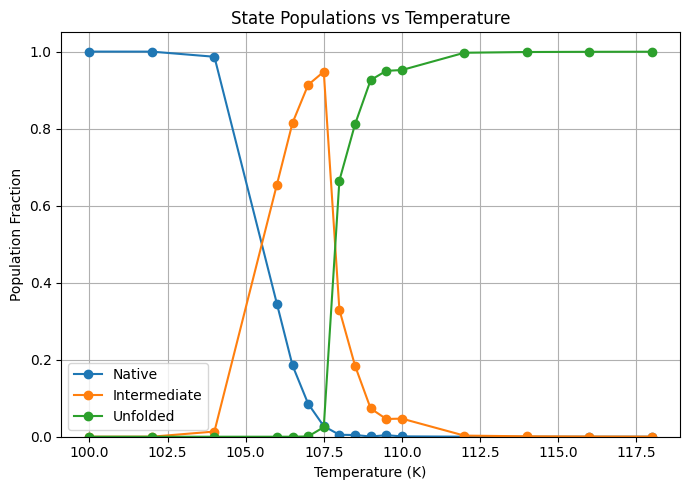


=== Free Energy Differences (kJ/mol) ===
102K  ΔG(N→I) = 7.85 kJ/mol
104K  ΔG(N→I) = 3.72 kJ/mol
106K  ΔG(N→I) = -0.56 kJ/mol
106K  ΔG(N→I) = -1.31 kJ/mol
106K  ΔG(I→U) = 9.25 kJ/mol
107K  ΔG(N→I) = -2.11 kJ/mol
107K  ΔG(I→U) = 6.35 kJ/mol
107K  ΔG(N→I) = -3.17 kJ/mol
107K  ΔG(I→U) = 3.26 kJ/mol
108K  ΔG(N→I) = -3.75 kJ/mol
108K  ΔG(I→U) = -0.63 kJ/mol
108K  ΔG(N→I) = -3.37 kJ/mol
108K  ΔG(I→U) = -1.34 kJ/mol
109K  ΔG(N→I) = -4.36 kJ/mol
109K  ΔG(I→U) = -2.30 kJ/mol
109K  ΔG(N→I) = -2.24 kJ/mol
109K  ΔG(I→U) = -2.76 kJ/mol
110K  ΔG(N→I) = -3.61 kJ/mol
110K  ΔG(I→U) = -2.75 kJ/mol
112K  ΔG(N→I) = -2.86 kJ/mol
112K  ΔG(I→U) = -5.45 kJ/mol
114K  ΔG(N→I) = -2.60 kJ/mol
114K  ΔG(I→U) = -6.51 kJ/mol
116K  ΔG(N→I) = -2.19 kJ/mol
116K  ΔG(I→U) = -7.31 kJ/mol
118K  ΔG(N→I) = -1.29 kJ/mol
118K  ΔG(I→U) = -8.15 kJ/mol


In [51]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

# === USER SETTINGS ===
dirs = ["100", "102", "104", "106", "106.5", "107","107.5", "108","108.5", "109", "109.5", "110", "112", "114", "116", "118"]  # temperature directories
kB = 0.008314462618  # kJ/mol/K

# === Q STATE CUTS (edit here if needed) ===
Q_unfolded_cutoff = 500    # unfolded: Q <= 500
Q_native_cutoff   = 1800   # native:   Q > 1950

def read_eQ(path):
    fname = os.path.join(path, "e-Q.dat")
    if not os.path.exists(fname):
        raise FileNotFoundError(f"{fname} not found")
    df = pd.read_csv(fname, sep=r'\s+', comment='#', header=None, engine='python')
    df = df.rename(columns={0:"Potential", 1:"Q"})
    return df.dropna().reset_index(drop=True)

# === Load data ===
blocks = []
for d in dirs:
    df = read_eQ(d)
    df["T"] = float(d)
    blocks.append(df)
frames = pd.concat(blocks, ignore_index=True)

temps = sorted(frames["T"].unique())
pop_native, pop_intermediate, pop_unfolded = [], [], []

print("\n=== Per-Replica Populations (Raw Fractions) ===")
for T in temps:
    dfT = frames[frames["T"]==T]
    qT = dfT["Q"].values

    is_unfolded    = qT <= Q_unfolded_cutoff
    is_native      = qT >  Q_native_cutoff
    is_intermediate = ~(is_unfolded | is_native)

    p_unf = is_unfolded.mean()
    p_nat = is_native.mean()
    p_int = is_intermediate.mean()

    pop_unfolded.append(p_unf)
    pop_native.append(p_nat)
    pop_intermediate.append(p_int)

    print(f"{int(T):3d}K  native={p_nat:.3f}  interm={p_int:.3f}  unfold={p_unf:.3f}")

# === Plot populations vs temperature ===
plt.figure(figsize=(7,5))
plt.plot(temps, pop_native, 'o-', label="Native")
plt.plot(temps, pop_intermediate, 'o-', label="Intermediate")
plt.plot(temps, pop_unfolded, 'o-', label="Unfolded")
plt.xlabel("Temperature (K)")
plt.ylabel("Population Fraction")
plt.title("State Populations vs Temperature")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# === Compute ΔG values for N⇆I and I⇆U ===
R = kB
print("\n=== Free Energy Differences (kJ/mol) ===")
for T, pn, pi, pu in zip(temps, pop_native, pop_intermediate, pop_unfolded):
    if pn > 0 and pi > 0:
        dG_NI = -R * T * np.log(pi/pn)
        print(f"{int(T):3d}K  ΔG(N→I) = {dG_NI:.2f} kJ/mol")
    if pi > 0 and pu > 0:
        dG_IU = -R * T * np.log(pu/pi)
        print(f"{int(T):3d}K  ΔG(I→U) = {dG_IU:.2f} kJ/mol")


## 🔍 State Populations Across Temperature
The population analysis reveals a clear N → I → U progression in the SMOG folding model. At low temperatures (100–106 K), the protein is almost exclusively in the native basin (Q > 1800). As the temperature increases to 108–110 K, the intermediate state (Q ≈ 1400–1800) becomes the most populated ensemble, indicating a well-defined partially folded structure that retains a significant fraction of native contacts. At temperatures above 112 K, the population shifts entirely into the unfolded regime (Q < 500), reflecting the onset of global unfolding. The derived free-energy differences ΔG(N→I) follow the same pattern, crossing zero near the midpoint of the N → I transition (~108–110 K), confirming that the intermediate becomes thermodynamically favored in this temperature window.

## 📉 Free-Energy Differences (ΔG)
The ΔG values computed from the state populations mirror the observed population shifts. Positive ΔG(N→I) at low temperature indicates strong native stability, while negative values above ~110 K indicate that the intermediate or unfolded states are more stable. These ΔG values quantify the relative stabilities of the three ensembles within the model and track the progressive destabilization of the native structure as temperature rises.

## ⚠️ Limitations of This Analysis 
This method has several important caveats. First, the SMOG/Go model produces model-level thermodynamics because it lacks explicit solvent and realistic energetic contributions, so ΔG values should not be interpreted as physical free energies. Second, the population and ΔG estimates depend on the choice of Q cutoffs that define native, intermediate, and unfolded states; while the qualitative N → I → U pattern is robust, the numerical values can shift slightly with different thresholds. Third, the analysis assumes equilibrium populations; insufficient sampling, especially in the unfolded region, can bias ΔG(I→U). Finally, Q is a one-dimensional reaction coordinate and may not fully resolve all structural sub-states, particularly within partially unfolded or highly heterogeneous regions.

## ✅ Overall
Taken together, the state populations and ΔG values provide a coherent and internally consistent picture of a three-state folding landscape. The native, intermediate, and unfolded ensembles are well separated; the intermediate becomes strongly stabilized around 108–110 K; and the thermodynamic progression captured in this model reflects a clear N → I → U transition when interpreted within the limitations of a SMOG structure-based potential.

-------------------------------
-----------------------------


### 📦 Extracting Structural Frames from Demuxed Trajectories  
All scripts below convert the **demuxed replica trajectories** (`*_trajout.xtc`) into **PDB frame sets**, allowing structural inspection and state visualization.  

In [52]:
%%bash
echo 1 1 | gmx_mpi trjconv -f 100__trajout.xtc -s 100/t-6ONJ.tpr -skip 50 -center -pbc mol -o 100__trajout.pdb

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'


In [53]:
%%bash
echo 1 1 | gmx_mpi trjconv -f 102__trajout.xtc -s 102/t-6ONJ.tpr -skip 50 -center -pbc mol -o 102_traj_comp.pdb

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'


Notes from visualization : 